# Etapa 1c — Ancho visible de los vasos

**Pregunta.** En la etapa 1 las máscaras de sanos salieron con vasos más anchos que las de retinopatía y glaucoma. ¿Es la forma de marcar de los expertos o una diferencia real en las imágenes? Se mide el ancho de los vasos **en la foto**, con el mismo criterio para todas, y se compara con el ancho **marcado**. Solo desarrollo.

## Cómo se mide (`visible_widths`, `profile_width`)

- 300 puntos al azar por imagen sobre la línea central de los expertos (semilla 2026), a más de 50 píxeles del borde del campo de visión y a más de 15 de bifurcaciones, cruces y puntas.
- En cada punto, perfil del canal verde sobre la perpendicular al vaso, de −L a +L con L = max(12, 3 × ancho marcado), cada 0,25 píxeles, promedio de 5 perfiles paralelos.
- Ancho visible: distancia entre los cruces de la mitad de profundidad (entre el fondo de cada lado y el mínimo).
- **No medible** si la zanja es poco profunda frente al ruido, si un lado no vuelve al fondo (borde oscuro, mancha u otro vaso dentro de la ventana), si el extremo todavía está sobre la ladera del vaso, o si el mínimo queda corrido del centro.

*(Antes de correr se cambió la ventana de 2,5 a 3 veces el ancho marcado, para poder medir vasos visibles hasta unas 2,4 veces más anchos que lo marcado; y se agregaron los controles de lado sin fondo y de ladera, que las pruebas sintéticas mostraron necesarios.)*

## Reglas fijadas antes de correr

- **Cociente marcado / visible** en cada punto medible; por imagen, la mediana de los puntos con ancho visible entre 4 y 12 píxeles (rango común a los grupos; en los más finos el desenfoque domina).
- **Ancho visible** por imagen: mediana de todos los puntos medibles.
- **Fracción no medible** por imagen.
- Diferencias sanos − retinopatía de la media por imagen, con intervalo al 95 % remuestreando personas dentro de cada grupo (5 y 8 personas; 2.000 remuestreos; semilla 2026). Glaucoma como tercer grupo.
- **Interpretación:**

| Cociente mayor en sanos (intervalo sin el cero) | Ancho visible mayor en sanos (intervalo sin el cero) | Conclusión |
|---|---|---|
| Sí | No | Forma de marcar |
| No | Sí | Diferencia real en las imágenes |
| Sí | Sí | Las dos cosas |
| No | No | No se explica con esta medida |

- **Control:** dentro de sanos, cociente de las imágenes más y menos comprimidas.


In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import SEED
from src.data import dev_ids, load_fov, load_image, load_split, load_vessels
from src.vessels import visible_widths

split = load_split().set_index("image")
ids = dev_ids()
rng = np.random.default_rng(SEED)
parts = []
for image_id in ids:
    green = load_image(image_id)[..., 1].astype(float)
    t = visible_widths(green, load_vessels(image_id), load_fov(image_id), 300, rng)
    t["image"] = image_id
    parts.append(t)
pts = pd.concat(parts, ignore_index=True)
pts = pts.join(split[["group", "person", "more_compressed"]], on="image")
pts["ratio"] = pts["marked_width"] / pts["visible_width"]
pts.to_csv(ROOT / "results" / "01c_puntos.csv", index=False)
print(f"{len(pts):,} puntos; medibles: {pts['visible_width'].notna().mean():.3f}")

9,000 puntos; medibles: 0.559


In [2]:
common = pts["visible_width"].between(4, 12)
per_image = pd.DataFrame({
    "cociente": pts[common].groupby("image")["ratio"].median(),
    "ancho_visible": pts.groupby("image")["visible_width"].median(),
    "ancho_marcado": pts.groupby("image")["marked_width"].median(),
    "no_medible": pts.groupby("image")["visible_width"].apply(lambda v: v.isna().mean()),
    "puntos_rango_comun": pts[common].groupby("image").size(),
}).join(split[["group", "person", "more_compressed"]])
per_image.groupby("group")[["cociente", "ancho_visible", "ancho_marcado", "no_medible", "puntos_rango_comun"]].agg(["mean", "min", "max"]).round(3).T

group                         dr        g        h
cociente           mean    0.520    0.559    0.799
                   min     0.469    0.499    0.686
                   max     0.610    0.611    1.041
ancho_visible      mean    9.620    9.762    9.604
                   min     8.338    8.733    8.307
                   max    10.968   11.537   10.958
ancho_marcado      mean    5.023    4.677    7.506
                   min     3.472    3.472    5.325
                   max     6.211    6.211    9.000
no_medible         mean    0.502    0.436    0.386
                   min     0.410    0.347    0.307
                   max     0.577    0.513    0.440
puntos_rango_comun mean   95.900  105.700  120.100
                   min    78.000   75.000  102.000
                   max   123.000  131.000  137.000

In [3]:
def boot_diff(col, a="h", b="dr", reps=2000, seed=SEED):
    """Diferencia de medias por imagen (a − b), remuestreando personas dentro de cada grupo."""
    r = np.random.default_rng(seed)
    out = []
    groups = {g: per_image[per_image.group == g] for g in (a, b)}
    persons = {g: d["person"].unique() for g, d in groups.items()}
    for _ in range(reps):
        means = []
        for g in (a, b):
            chosen = r.choice(persons[g], len(persons[g]), replace=True)
            d = groups[g].set_index("person").loc[chosen]
            means.append(d[col].mean())
        out.append(means[0] - means[1])
    est = groups[a][col].mean() - groups[b][col].mean()
    lo, hi = np.percentile(out, [2.5, 97.5])
    return pd.Series({"diferencia": est, "límite inferior": lo, "límite superior": hi})

table = pd.DataFrame({
    f"{col}: {a} − {b}": boot_diff(col, a, b)
    for col in ("cociente", "ancho_visible", "no_medible")
    for a, b in (("h", "dr"), ("h", "g"))
}).T
table.round(3)

,diferencia,límite inferior,límite superior
cociente: h − dr,0.279,0.202,0.370
cociente: h − g,0.240,0.164,0.333
ancho_visible: h − dr,-0.016,-0.742,0.700
ancho_visible: h − g,-0.158,-1.259,0.804
no_medible: h − dr,-0.116,-0.163,-0.077
no_medible: h − g,-0.050,-0.100,0.002


**Control de compresión dentro de sanos.**

In [4]:
print(per_image[per_image.group == "h"].groupby("more_compressed")[["cociente", "ancho_visible", "no_medible"]].mean().round(3))

                 cociente  ancho_visible  no_medible
more_compressed                                     
False               0.893          8.976       0.377
True                0.736         10.022       0.392


**Ancho marcado contra ancho visible** (puntos medibles, una muestra de cada grupo). La línea es marcado = visible.

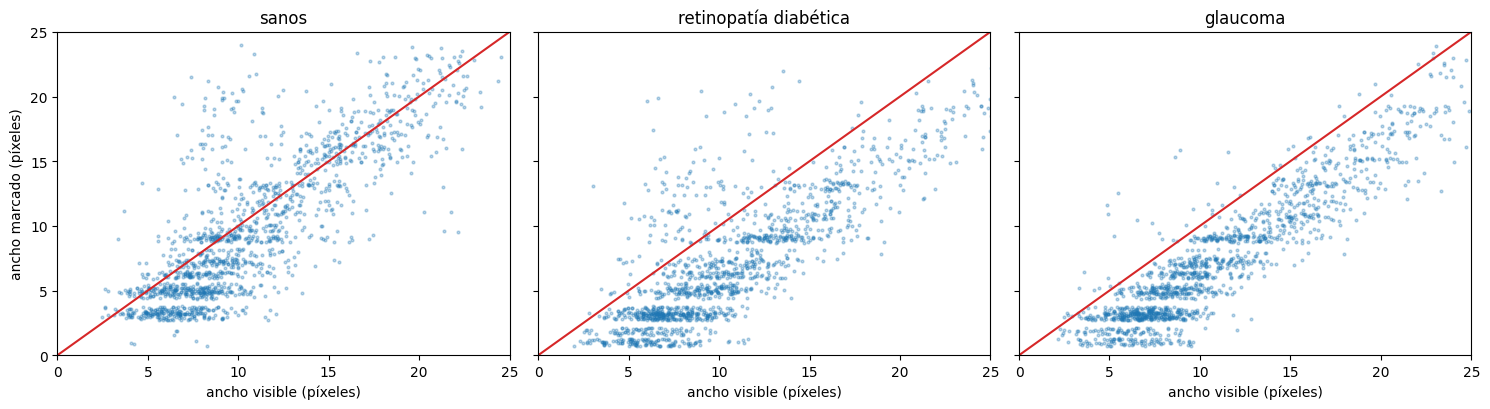

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), sharex=True, sharey=True)
names = {"h": "sanos", "dr": "retinopatía diabética", "g": "glaucoma"}
for a, g in zip(ax, ("h", "dr", "g")):
    d = pts[(pts.group == g) & pts.visible_width.notna()]
    d = d.sample(min(len(d), 1500), random_state=SEED)
    a.scatter(d.visible_width, d.marked_width + np.random.default_rng(1).uniform(-0.3, 0.3, len(d)),
              s=4, alpha=0.3)
    a.plot([0, 25], [0, 25], color="C3")
    a.set_title(names[g]); a.set_xlabel("ancho visible (píxeles)")
ax[0].set_ylabel("ancho marcado (píxeles)")
ax[0].set_xlim(0, 25); ax[0].set_ylim(0, 25)
plt.tight_layout()

## Decisión (escrita después de correr)

**Conclusión según la regla: es la forma de marcar.**

- **Cociente marcado / visible:** sanos 0,80; retinopatía 0,52; glaucoma 0,56. Diferencia sanos − retinopatía **0,28** (intervalo 0,20 a 0,37) y sanos − glaucoma 0,24 (0,16 a 0,33): los expertos marcaron los vasos de sanos relativamente más anchos.
- **Ancho visible:** sanos 9,60; retinopatía 9,62; glaucoma 9,76 píxeles. Diferencia sanos − retinopatía −0,02 (−0,74 a 0,70): **los vasos que se ven en la foto miden lo mismo** en los tres grupos.
- **Control de compresión:** dentro de sanos el cociente es 0,89 en las menos comprimidas y 0,74 en las más comprimidas; las dos siguen muy por encima de retinopatía (0,52, casi todas menos comprimidas). La compresión ensancha un poco lo visible (9,0 contra 10,0 píxeles), pero no explica la diferencia.

**Observaciones.**
- En todos los grupos el cociente es menor que 1: los expertos marcan más angosto que el ancho a mitad de profundidad, que con el desenfoque de la foto resulta amplio. Lo que importa es la diferencia entre grupos, no el valor absoluto.
- Se pudo medir el 56 % de los puntos (61 % en sanos, 50 % en retinopatía, 56 % en glaucoma). Los demás se descartaron por vasos vecinos, bordes o poco contraste. Esta diferencia en lo medible también se informa.

**Consecuencias.** La diferencia de ancho y de proporción de vasos entre las máscaras de sanos y de los otros grupos es de las máscaras, no de las retinas. Las medidas por píxel van a tratar distinto a cada grupo. Esto justifica agregar como resultado secundario una medida basada en la línea central (a proponer como desvío del plan), y obliga a interpretar la etapa 7 con cuidado: una diferencia de proporción de vasos entre grupos en las máscaras de los expertos no es una diferencia biológica.
